## Ejercicio 4.1

### Lucas-kanade optical flow

In [1]:
#| include: false
%load_ext autoreload
%autoreload 2

In [2]:
#| include: false
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from sklearn.cluster import MeanShift, estimate_bandwidth
from sklearn.datasets import make_blobs

from pathlib import Path

from miia_pec1.plot import plot_image, draw_flow, draw_flow_hsv, draw_flow_warp, draw_flow_registration

plt.rcParams['figure.figsize'] = (6, 4.5)
plt.rcParams['figure.dpi'] = 100

In [177]:
#| include: false
ROOT_DIR = Path.cwd()
OPTICAL_FLOW_DIR = ROOT_DIR / 'data' / 'opticalFlow'
OUT_DIR = ROOT_DIR / 'out' / 'seguimiento'

# Colores en el espacio BRG
BLUE = (255, 0, 0)
GREEN = (0, 255, 0)
RED = (0, 0, 255)

In [4]:
#| include: false
# Criterio de terminación para el algoritmo:
#   - Como máximo 10 iteraciones
#   - S el cambio entre iteracciones es de < 0.03 píxeles
CRITERIA = (cv.TERM_CRITERIA_EPS | cv.TERM_CRITERIA_COUNT, 10, 0.03)

# Parámetros para la detección de esquinas para ShiTomasi
feature_params = dict( maxCorners = 100,
                       qualityLevel = 0.3,
                       minDistance = 7,
                       blockSize = 7 )

# Parámetros para el algoritmo lukas kanade
lk_params = dict( winSize  = (15, 15),
                  maxLevel = 2,
                  criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_COUNT, 10, 0.03))

# Array de colores aleatorios
color = np.random.randint(0, 255, (100, 3))

In [5]:
#| include: false
cap = cv.VideoCapture(OPTICAL_FLOW_DIR / 'slow_traffic_small.mp4')

In [6]:
#| include: false
frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))
fps = int(cap.get(cv.CAP_PROP_FPS))
height = int(cap.get(cv.CAP_PROP_FRAME_HEIGHT))
width = int(cap.get(cv.CAP_PROP_FRAME_WIDTH))

print('Información del video')
print('='*40)
print('size:'.rjust(10), f'({height}, {width})')
print('frames:'.rjust(10), f'{frames}')
print('fps:'.rjust(10), f'{fps} frames por segundo')
print('duración:'.rjust(10), f'{(frames/fps):.2f} segundos')

Información del video
     size: (360, 640)
   frames: 914
      fps: 29 frames por segundo
 duración: 31.52 segundos


In [7]:
#| include: false
_, old = cap.read()
old_gray = cv.cvtColor(old, cv.COLOR_BGR2GRAY)

In [8]:
#| include: false

p0 = cv.goodFeaturesToTrack(old_gray, mask=None, **feature_params)

El algoritmo de Lucas-Kanade permite estimar el movimiento aparente de determinados puntos de interés entre fotogramas consecutivos de un vídeo. Este enfoque se conoce como flujo óptico siperso, ya que únicamente realiza el seguimiento de un conjunto seleccionado de puntos, en lugar de calcular el desplazamiento de todos los puntos de la imagen.

Para se seleccionar el conjunto de puntos deseguimiento se utiliza el detector de esquinas **Shi-Tomasi**. Este algoritmo analiza los gradientes de intensidad en regiones locales de la imagen para identificar puntos con variaciones altas en las dos direcciones independientes.

En la @fig-shi-tomasi-corner-detection, se muestran dos puntos seleccionados y sus respectivas ventanas de respuesta con las puntuaciones obtenidas con `cv.cornerMinEigenVal()`, que calcula el menor valor propio de la matriz de gradientes en cada posición de la imagen. Los puntos seleccionados presentan puntuaciones de 0.0678 y 0.0346, respectivamente, ambos corresponden a máximos locales y constituyen candidatos adecuados para el seguimiento óptico.

::: {.callout-note}
La matriz de gradientes, resume cómo varía la intensidad en diferentes direcciones dentro de una región.

$$
M=
\begin{bmatrix}
\sum I_x^2 & \sum I_xI_y\\
\sum I_xI_y & \sum I_y^2
\end{bmatrix}
$$

A partir de esta matriz se obtienen dos valores propios, $(\lambda_1 y \lambda_2)$, que describen la magnitud de las variaciones de intensidad en las dos direcciones principales de la región. Shi-Tomasi se queda con el menor valor propio.

$$
R=\min(\lambda_1,\lambda_2)
$$

Porque para considerar un región buena como esquina se busca que las dos direcciones presenten variaciones significativas, no sólo una.
:::

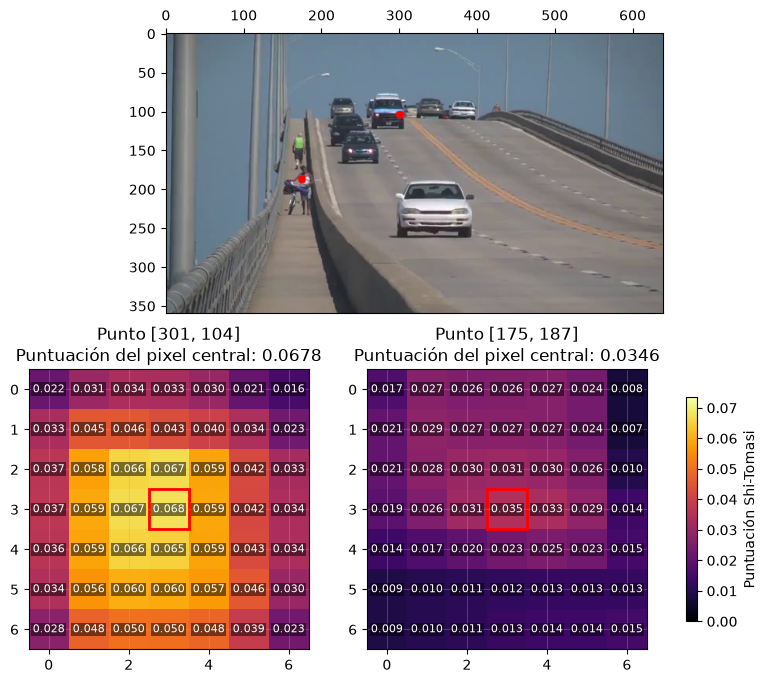

In [9]:
#| echo: false
#| label: fig-shi-tomasi-corner-detection
#| fig-cap: "Detección de puntos de interés mediante Shi-Tomasi y respuesta local de esquina"
PAIR_POINTS = [1, 6]
block_size = feature_params['blockSize']
radio = block_size // 2

fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2)

ax1 = fig.add_subplot(gs[0, :])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])

img_plt = old.copy()

for p in p0[PAIR_POINTS]:
    x, y = p.ravel().astype(int)
    img_plt = cv.circle(img_plt, (x, y), 5, RED, -1)

plot_image(img_plt, convert=cv.COLOR_BGR2RGB, ax=ax1, axis=True)


min_eign_value = cv.cornerMinEigenVal(old_gray, block_size, 3)
max_score = min_eign_value.max()


for p, ax in zip(p0[PAIR_POINTS], (ax2, ax3)):    
    x, y = [int(i) for i in p.ravel()]
    slice_x = slice(x-radio, x+radio+1)
    slice_y = slice(y-radio, y+radio+1)

    scores = min_eign_value[slice_y, slice_x]
    
    im = ax.imshow(
        scores,
        cmap='inferno',
        vmin=0,
        vmax=max_score)

    for row in range(block_size):
        for col in range(block_size):
            score = scores[row, col]
            
            ax.text(
                col, row,
                f'{score:.3f}',
                ha='center',
                va='center',
                fontsize=8,
                color='white',
                bbox=dict(
                    facecolor='black',
                    alpha=0.5,
                    edgecolor='none',
                    pad=1
            ))

    ax.add_patch(plt.Rectangle(
        (radio - 0.5, radio - 0.5), 1, 1, fill=False, edgecolor='red', linewidth=2
    ))
    ax.grid(alpha=0.3)
    ax.set_title(f'Punto [{x}, {y}]\nPuntuación del pixel central: {scores[3, 3]:.4f}')
    
fig.colorbar(im, ax=(ax2, ax3), shrink=0.8, label="Puntuación Shi-Tomasi")
plt.show()

In [10]:
#| include: false
_, frame = cap.read()
frame_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

Una vez detectados los puntos de interés, el algoritmo Luca-Kanade estima sus nuevas posiciones en el siguiente fotograma mediante `cv.calcOpticalFlowPyrLK()`.

Este método se basa en dos hipótesis principales: que la intensidad de un mismo punto permanece contante entre fotogramas consecutivos y que los píxeles de una pequeña región presentan un movimiento similar. A partir de estas hipótesis, Lucas-Kanade relaciona los gradientes espaciales y temporales de intensidad mediante la ecuación del flujo óptico:

$$
I_xu+I_yv+I_t=0
$$

donde $I_x$ e $I_y$ representan los gradientes espaciales, $I_t$ el gradiente temporal y $(u,v)$ las componentes del movimiento. Como esta ecuación contiene dos incógnitas, el algoritmo considera una ventana de píxeles vecinos y supone que comparten un movimiento similar. De esta manera, obtiene un sistema de ecuaciones que resuelve mediante mínimos cuadrados para estimar el desplazamiento del punto [@opencv_optical_flow].

En la @fig-lukas-kanade-2-frames se muestra el desplazamiento estimado de varios puntos característicos de un vehículo entre dos fotogramas consecutivos. Los puntos verdes representan las posiciones anteriores y los azules las posiciones estimadas en el nuevo fotograma.

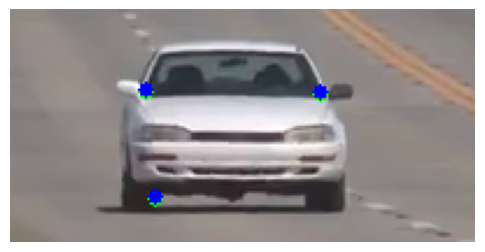

In [11]:
#| echo: false
#| label: fig-lukas-kanade-2-frames
#| fig-cap: "Desplazamiento de puntos característicos entre dos fotogramas mediante Lucas-Kanade"
img_plt = frame.copy()

p1, st, err = cv.calcOpticalFlowPyrLK(old_gray, frame_gray, p0, None, **lk_params)

for old, new in zip(p0, p1):
    a, b = [int(i) for i in old.ravel()]
    c, d = [int(i) for i in new.ravel()]

    img_plt = cv.circle(img_plt, (int(a), int(b)), 3, GREEN, -1)
    img_plt = cv.circle(img_plt, (int(c), int(d)), 3, BLUE, -1)



plot_image(img_plt[175:275, 250:450], convert=cv.COLOR_BGR2RGB)
plt.show()

In [12]:
#| include: false
ret, old_frame = cap.read()
old_gray = cv.cvtColor(old_frame, cv.COLOR_BGR2GRAY)
p0 = cv.goodFeaturesToTrack(old_gray, mask = None, **feature_params)

mask = np.zeros_like(old_frame)

while True:
    ret, frame = cap.read()
    if not ret:
        print('No frames grabbed!')
        break

    frame_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    p1, st, err = cv.calcOpticalFlowPyrLK(old_gray, frame_gray, p0, None, **lk_params)

    if p1 is not None:
        good_new = p1[st==1]
        good_old = p0[st==1]

    for i, (new, old) in enumerate(zip(good_new, good_old)):
        a, b = new.ravel()
        c, d = old.ravel()
        mask = cv.line(mask, (int(a), int(b)), (int(c), int(d)), color[i].tolist(), 2)
        frame = cv.circle(frame, (int(a), int(b)), 5, color[i].tolist(), -1)
    img = cv.add(frame, mask)

    old_gray = frame_gray.copy()
    p0 = good_new.reshape(-1, 1, 2)

No frames grabbed!


El seguimiento sucesivo de estos puntos permite reconstruir sus trayectoria a lo largo del vídeo, como se observa en la @fig-lukas-kanade-video.

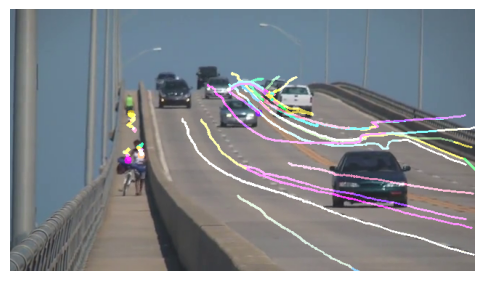

In [13]:
#| echo: false
#| label: fig-lukas-kanade-video
#| fig-cap: "Trayectorias de puntos característicos durante el seguimiento óptico"

plot_image(img, convert=cv.COLOR_BGR2RGB)
plt.show()

::: {.callout-warning}
Una de las principales limitaciones de Lucas-Kanade es que en la regiones uniformes o suavizadas de la imagen, las variaciones espaciales de intensidad son pequeñas y, por tanto, no existe suficiente información para determinar de forma fiable el movimiento. Cuando una región presenta una intensidad prácticamente uniforme:

$$
I_x\approx0,\qquad I_y\approx0
$$

Por tanto:

$$
M\approx
\begin{bmatrix}
0&0\\
0&0
\end{bmatrix}
$$

Y los valores propios serán aproximadamente:

$$
\lambda_1\approx0,\qquad\lambda_2\approx0
$$

Esto implica que no hay suficiente información para determinar de manera fiable las dos componentes del movimiento.
:::

### Dense optical flow

El programa **optical_flow1.py** utiliza el algoritmo de Gunnar Farneback para calcular el flujo óptico denso. A diferencia del método de Lucas-Kanade, este enfoque calcula un vector de desplazamiento para cada posición de la imagen.

El algoritmo Farnebäck estima el vector de desplazamiento
$(u,v)$ que satisface aproximadamente la relación:

$$
I_1(x+u,\ y+v) \approx I_0(x,y)
$$

donde $I_0$ e $I_1$ representan dos fotogramas consecutivos
de una secuencia de vídeo.

El movimiento aparerente entre dos fotogramas se calcula mediante aproximaciones polinómicas de segundo grado. Estas aproximaciones permiten describir las variaciones de intensidad de una región y analizar cómo cambian entre dos fotogramas para determinar su desplazamiento [@farneback2003twoframe].

En la @fig-vtest-consecutive-frames se muestran dos fotogramas consecutivos de la secuencia analizada, en ella se observa el desplazamiento de varios peatones.

In [14]:
#| include: false
cap = cv.VideoCapture(OPTICAL_FLOW_DIR / 'vtest.mp4')

ret, old_frame = cap.read()
old_gray = cv.cvtColor(old_frame, cv.COLOR_BGR2GRAY)

hsv = np.zeros_like(old_frame)
hsv[..., 1] = 255

ret, frame = cap.read()
gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

flow = cv.calcOpticalFlowFarneback(old_gray, gray, None, 0.5, 3, 15, 3, 5, 1.2, 0)

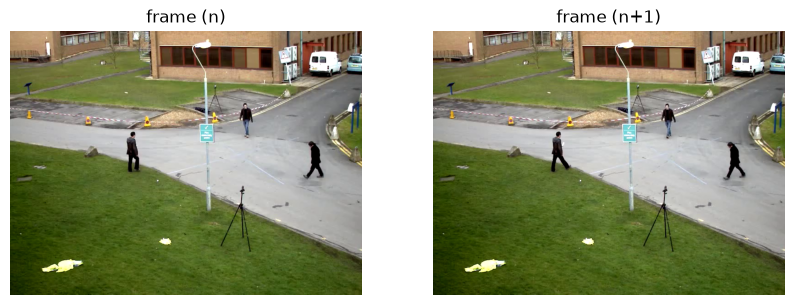

In [15]:
#| echo: false
#| label: fig-vtest-consecutive-frames
#| fig-cap: "Fotogramas consecutivos utilizados para estimar el flujo óptico denso"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))

plot_image(old_frame, ax=ax1, convert=cv.COLOR_BGR2RGB, title="frame (n)")
plot_image(frame, ax=ax2, convert=cv.COLOR_BGR2RGB, title="frame (n+1)")

plt.show()

Mediante la función `cv.calcOpticalFlowFarneback()` se obtiene los vectores de desplazamiento $(f_x, f_y)$ de cada píxel entre los dos fotogramas.

En la @fig-farneback-dense-optical-flow se muestran tres formas de representar el flujo óptico estimado:
- **(a) Representación vectorial:** se visualizan los deplazamientos mediante segmentos dibujados sobre una malla representada sobre la imagen. Su orientación indica la dirección del movimiento y su longitud la magnitud del desplazamiento.
- **(b) Representación HSV:** se codifica el flujo óptico mediante colores, el tono representa la dirección del movimiento y el brillo su magnitud normalizada, las regiones con mayor desplazamiento aparecen más brillantes.
- **\(c\) Deformación de la imagen:** se utiliza el campo de de flujo optico para remuestrear la imagen aplicando un mapeo inverso, para visualizar el efecto estimado del desplazamiento en la imagen.

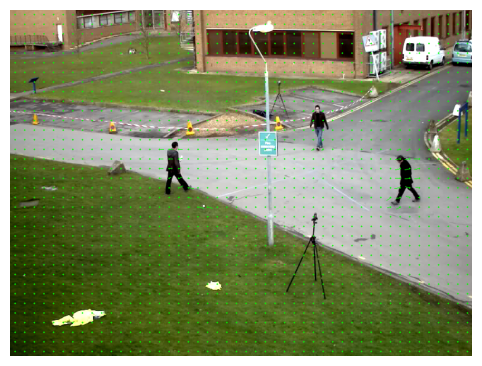

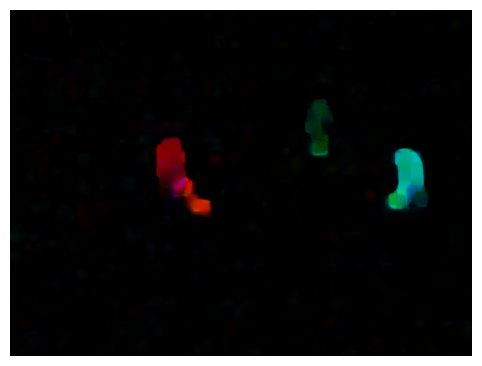

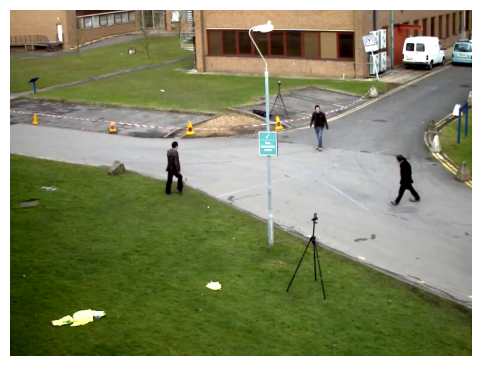

In [16]:
#| echo: false
#| label: fig-farneback-dense-optical-flow
#| fig-cap: "Visualización del flujo óptico denso estimado mediante Farnebäck"
#| fig-subcap:
#|  - "Vectores de desplazamiento muestreados regularmente"
#|  - "Representación HSV de la dirección y magnitud del movimiento"
#|  - "Deformación de la imagen mediante mapeo inverso a partir del campo de flujo óptico"
#| layout-ncol: 3
plot_image(draw_flow(frame.copy(), flow), convert=cv.COLOR_BGR2RGB)
plot_image(draw_flow_hsv(flow), convert=cv.COLOR_BGR2RGB)
plot_image(draw_flow_warp(old_frame.copy(), flow.copy()), convert=cv.COLOR_BGR2RGB)

plt.show()

Otra forma de visualizar el flujo óptico consiste en construir una imagen RGB, asignando la imagen transformada mediante el campo de flujo al canal rojo y la imagen de referencia a los canales verde y azul.

Cuando ambas imágenes coinciden, el resultado aparece en escala de grises, mientras que las diferencias se manifiestan mediante tonalidades rojizas o cian, permitiendo identificar posibles errores de registro.

En la @fig-dense-optical-flow-registration se observa cómo la compensación del movimiento mediante Farnebäck reduce las diferencias entre los fotogramas.

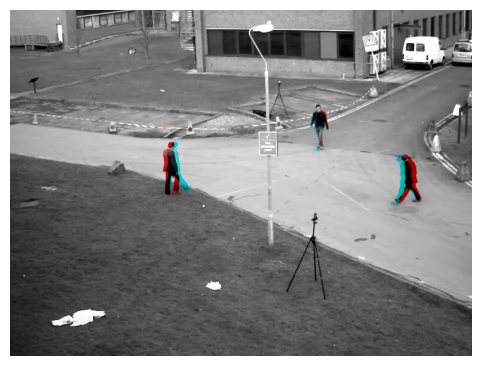

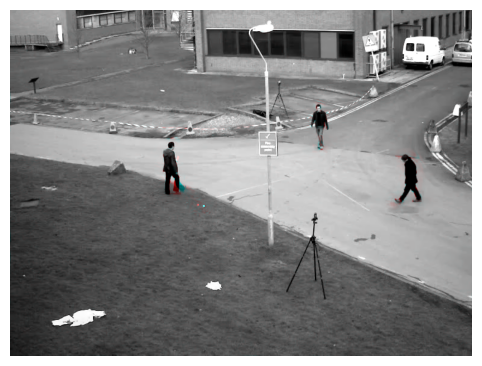

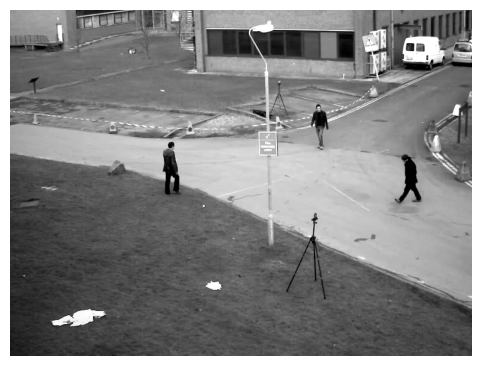

In [17]:
#| echo: false
#| label: fig-dense-optical-flow-registration
#| fig-cap: "Visualización flujo óptico"
#| fig-subcap:
#|  - "Imagen sin registrar"
#|  - "Secuencia registrada"
#|  - "Objetivo"
#| layout-ncol: 3

seq_img, reg_img, target_img = draw_flow_registration(gray, old_gray, flow)

plot_image(seq_img)
plot_image(reg_img)
plot_image(target_img)

plt.show()

## Ejercicio 4.2

In [147]:
#| include: false
# Simulación de puntos distribuidos en torno a tres centros
centers = [[1, 1], [1, -1], [-1, -1]]
X, _ = make_blobs(n_samples=1_000, centers=centers, cluster_std=0.6)

# Se aplica MeanShift para localizar las regiones alta densidad
bandwidth = estimate_bandwidth(X, quantile=0.2, n_samples=500)
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms.fit(X)

labels = ms.labels_
cluster_centers = ms.cluster_centers_
labels_unique = np.unique(labels)
n_clusters_ = len(labels_unique)

El algoritmo de **Mean Shift**, situa una ventana alrededr de un punto incial, calcula la media de los puntos contenidos en ella y desplaza la ventana a esa posición, repitiendo el proceso hasta que el desplazamiento es prácticamente nulos permitiendonos localizar zonas de alta densidad como se muestra en la @fig-mean-shift.

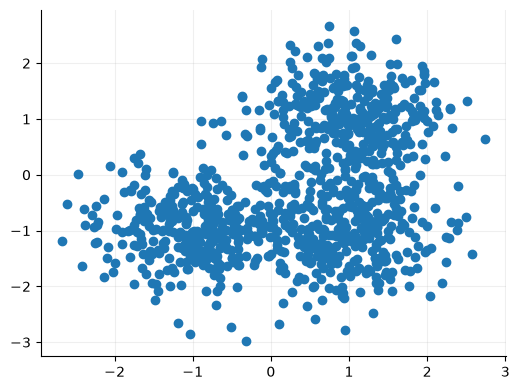

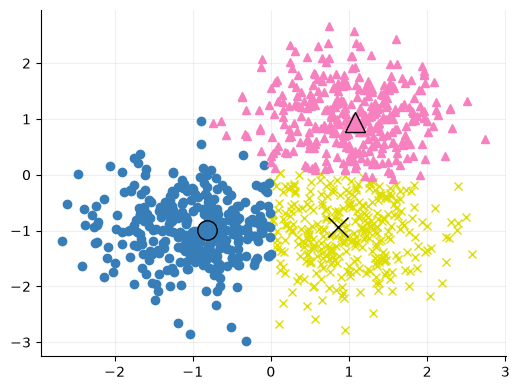

In [149]:
#| echo: false
#| label: fig-mean-shift
#| fig-cap: "Identificación de regiones de alta densidad mediante Mean Shift"
#| fig-subcap:
#|  - "Distribución inicial de los puntos"
#|  - "Agrupaciones y centros detectados mediante Mean Shift"
#| layout-ncol: 2
 
_, ax1 = plt.subplots()
_, ax2 = plt.subplots()

colors = ["#dede00", "#377eb8", "#f781bf"]
markers = ["x", "o", "^"]

ax1.plot(X[:, 0], X[:, 1], 'o')

for k, col in zip(range(n_clusters_), colors):
    my_members = labels == k
    cluster_center = cluster_centers[k]
    ax2.plot(X[my_members, 0], X[my_members, 1], markers[k], color=col)
    ax2.plot(
        cluster_center[0],
        cluster_center[1],
        markers[k],
        markerfacecolor=col,
        markeredgecolor="k",
        markersize=14,
    )

for ax in [ax1, ax2]:   
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(alpha=0.2)


plt.show()

¿Cómo podemos aplicar Mean Shift para realizar el seguimiento de una mano mediante una webcam?

Para realizar el seguimiento de una mano se parte de una imagen de referencia, captura por la webcam, de la que se selecciona una región de interés (ROI) que contiene la mano.

Esta región se convierte al espacio de color HSV y se aplica una máscara para seleccionar los píxeles cuyos valores se encuentran dentro de un intervalo determinado. A continuación, se calcula el histograma del canal de tono (H) utilizando los píxeles seleccionados con la máscara y se normalizan los valores entre 0 y 255.

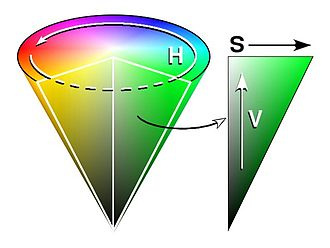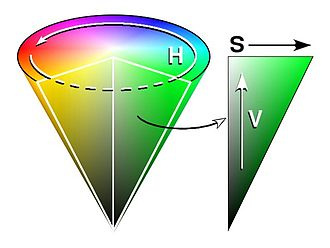

En la @fig-mean-shift-mask se muestra la región de interés, la máscara obtenida y el histograma normalizado que caracteriza los tonos de la mano.

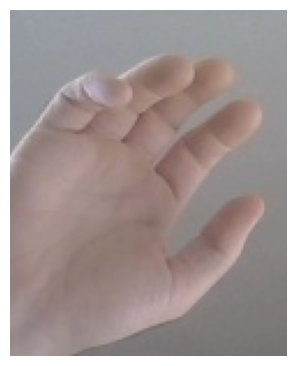

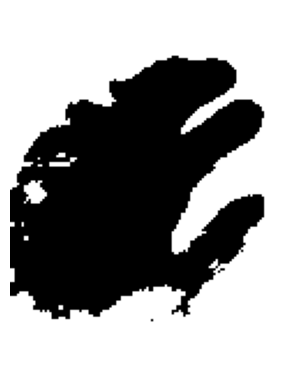

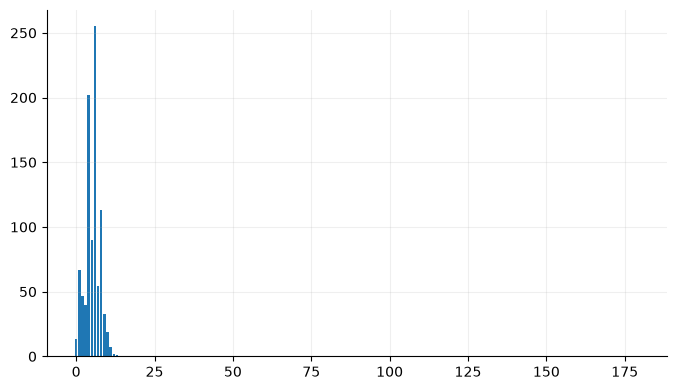

In [196]:
#| echo: false
#| label: fig-mean-shift-mask
#| fig-cap: "Obtención del modelo de color de la mano mediante segmentación HSV e histograma normalizado"
#| fig-subcap:
#|  - "Región de interés (ROI) de la mano"
#|  - "Máscara binaria obtenioda mediante umbrales HSV"
#|  - "Histograma normalizado del canal H"
#| layout-ncol: 3
img = cv.imread(OUT_DIR / 'seguimiento.jpg')

# Localización de la mano en la imagen de referencia
x, y, w, h = 210, 110, 120, 150

roi = img[y:y+h, x:x+w]

# Espacio de color HSV
hsv_roi =  cv.cvtColor(roi, cv.COLOR_BGR2HSV)

mask = cv.inRange(hsv_roi, np.array((0., 35.,70.)), np.array((20.,130.,255.)))

roi_hist = cv.calcHist([hsv_roi],[0],mask,[180],[0,180])
cv.normalize(roi_hist,roi_hist,0,255,cv.NORM_MINMAX)


plot_image(roi, convert=cv.COLOR_BGR2RGB)
plot_image(mask)

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(len(roi_hist))
ax.bar(bins, roi_hist)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(alpha=.2)


plt.show()

Con el histograma se calcula la retroproyección, utilizando `cv.calcBackProject()`, funciona asignado a cada píxel de la imagen un valor según la correspondencia de su tono, con los tonos normalizados del histograma. De esta forma, se genera una imagen en escala de grises donde los tonos más similares a los de la mano se presentan más oscuros.

En la @fig-mean-shift-on-image-1 se muestra la retroproyección obtenida con la imagen de referencia. En la  @fig-mean-shift-on-image-2 se representan las agrupaciones detectadas al aplicar MeanShift sobre las coordenadas de los píxeles seleleccionados, podemos observar que, además de la mano aparecen otras regiones similares, especialmente alrededor de la cara.

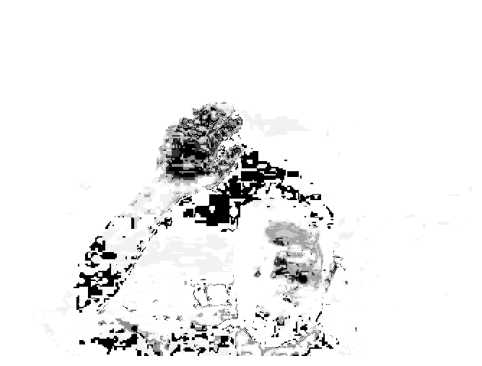

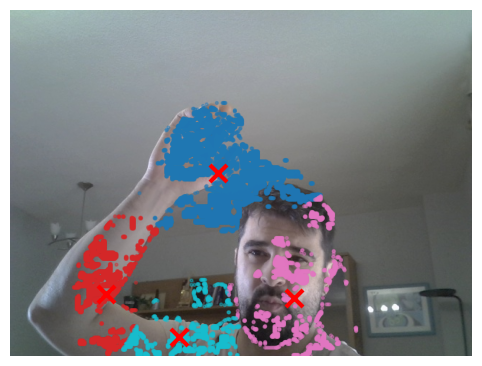

In [195]:
#| echo: false
#| label: fig-mean-shift-on-image
#| fig-cap: "Identificación de regiones con colores similares a los de la mano mediante retroproyección y agrupamiento MeanShift"
#| fig-subcap:
#|  - "Retroproyección del histograma de color"
#|  - "Agrupaciones espaciales identificadas mediante MeanShift"
#| layout-ncol: 2
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)
dst = cv.calcBackProject([hsv],[0],roi_hist,[0,180],1)

# Aplicar Mean-Shift sobre la imagen de backproject, para facilitar el ejemplo se filtran los píxeles con mayor
# correspondencia con la mano
y, x = np.where(dst > 255//2)

X = np.column_stack((x, y)).astype(np.float32)

bandwidth = estimate_bandwidth(X, quantile=0.2, n_samples=500)
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
ms.fit(X)

labels = ms.labels_
centers = ms.cluster_centers_


plot_image(dst)
ax = plot_image(img, convert=cv.COLOR_BGR2RGB)
ax.scatter(
    X[:, 0], X[:, 1],
    c=labels,
    cmap='tab10',
    s=4,
    alpha=0.4
)
ax.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='x',
    color='red',
    s=150,
    linewidths=3
)


plt.show()

Para realizar el seguimiento en tiempo real utiliza el comando `uv run miia-pec1 meanshift`.

Algunos consideraciones a tener en cuenta:

- Necesita una ventana inicial para realizar el seguimiento.
- Para que el seguimiento sea correcto es necesario que las condiciones de iluminación sean similares a los de la captura de referencia.
- El tamaño de la ventana es fijo, no se adapta aunque cambie la escala de la mano.
- Se pierde el foco al salir de plano, se realiza un movimiento brusco hacia la ventana inicial o zonas de tonalidades similares a la mano como la cara.


In [197]:
#| output: false
# Este comando realiza el seguimiento en la webcam de un objeto usando meanshift
# Recibe una imagen de referencia, el área de interés y los valores mínimo y máximo con los que generar la máscara para el seguimiento.
!uv run miia-pec1 meanshift \
    --track-window 210,110,120,150 \
    --mask-min 0,35,70 \
    --mask-max 20,130,255 \
    --image-ref {OUT_DIR / 'seguimiento.jpg'} \
    --device 2 \
    --outfile {OUT_DIR / 'ejemplo.mp4'}